#**Preperd By:**

1- BashayerAlrashidi
2- BodurAlqahtani
3- Lena Alenazi


##Interduction                                                  
 **MNIST Dataset:**
The MNIST dataset is a large database of handwritten digits commonly used for training various image processing systems. It contains 70,000 images of handwritten digits from 0 to 9, making it a staple dataset for benchmarking classification algorithms.

![MNIST Sample](https://upload.wikimedia.org/wikipedia/commons/2/27/MnistExamples.png)

# 1- Data Loading and Preprocessing:


## Libraries Import & Data Loading:

In [ ]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# Download the MNIST dataset
mnist = fetch_openml('mnist_784', version=1)
X, y = mnist['data'], mnist['target']
# Normalize pixel values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

/usr/local/lib/python3.10/dist-packages/sklearn/datasets/_openml.py:968: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [ ]:
print(X.shape)

(70000, 784)


In [ ]:
print(y.shape)

(70000,)


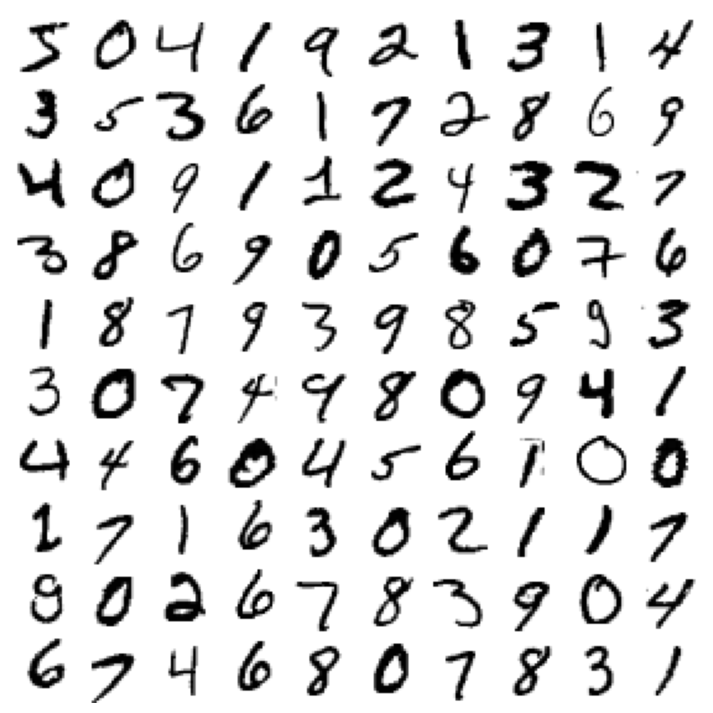

In [ ]:
def plot_digits(instances, images_per_row=10, **options):
    size = 28
    n_rows = (len(instances) - 1) // images_per_row + 1
    n_empty = n_rows * images_per_row - len(instances)
    padded_instances = np.concatenate([instances, np.zeros((n_empty, size * size))], axis=0)
    image_grid = padded_instances.reshape((n_rows, images_per_row, size, size))
    big_image = image_grid.transpose(0, 2, 1, 3).reshape(n_rows * size, images_per_row * size)
    plt.imshow(big_image, cmap=mpl.cm.binary, **options)
    plt.axis("off")
plt.figure(figsize=(9, 9))
# Select the first 100 images from the MNIST dataset
images = X[:100]
plot_digits(images, images_per_row=10)
plt.show()

# 2- Baseline Model with Traditional Machine Learning Algorithms

In [ ]:
# Baseline Model: Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)
y_pred = logreg.predict(X_test)
# Evaluate Logistic Regression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='weighted')
recall = recall_score(y_test, y_pred, average='weighted')
f1 = f1_score(y_test, y_pred, average='weighted')
print(f"Evaluation results for Logistic Regression :")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Evaluation results for Logistic Regression :
Accuracy: 0.912952380952381
Precision: 0.9126581531308037
Recall: 0.912952380952381
F1-score: 0.9127256135816658


# 3- Ensemble of Machine Learning Algorithms

In [ ]:
# Decision tree
from sklearn.tree import DecisionTreeClassifier
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_train, y_train)
y_pred_dt = decision_tree.predict(X_test)
accuracy = accuracy_score(y_test, y_pred_dt)
precision = precision_score(y_test, y_pred_dt, average='weighted')
recall = recall_score(y_test, y_pred_dt, average='weighted')
f1 = f1_score(y_test, y_pred_dt, average='weighted')
print(f"Evaluation results for Decision Tree :")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Evaluation results for Decision Tree :
Accuracy: 0.8681428571428571
Precision: 0.8678112904571613
Recall: 0.8681428571428571
F1-score: 0.867894764581193


In [ ]:
# Random Forest
from sklearn.ensemble import RandomForestClassifier
random_forest = RandomForestClassifier(n_estimators=100, random_state=42)
random_forest.fit(X_train, y_train)
y_pred_rf = random_forest.predict(X_test)
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_rf, average='weighted')
recall = recall_score(y_test, y_pred_rf, average='weighted')
f1 = f1_score(y_test, y_pred_rf, average='weighted')
print(f"Evaluation results for Random Forest:")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Evaluation results for Random Forest:
Accuracy: 0.9667142857142857
Precision: 0.966690928362643
Recall: 0.9667142857142857
F1-score: 0.9666907929891879


In [ ]:
# Support Vector Machines
from sklearn.svm import SVC
svm = SVC(kernel='rbf', gamma='scale')
svm.fit(X_train, y_train)
y_pred_svm = svm.predict(X_test)
accuracy = accuracy_score(y_test, y_pred_rf)
precision = precision_score(y_test, y_pred_svm, average='weighted')
recall = recall_score(y_test, y_pred_svm, average='weighted')
f1 = f1_score(y_test, y_pred_svm, average='weighted')
print(f"Evaluation results for Support Vector Machines :")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Evaluation results for Support Vector Machines :
Accuracy: 0.9667142857142857
Precision: 0.9624908637361649
Recall: 0.9622380952380952
F1-score: 0.9622564623264184


In [ ]:
# Combine the predictions of individual models using voting
from sklearn.ensemble import VotingClassifier
voting_clf = VotingClassifier(estimators=[('rf', random_forest), ('dt', decision_tree), ('svm', svm)], voting='hard')
voting_clf.fit(X_train, y_train)
y_pred_voting = voting_clf.predict(X_test)
# Evaluate the ensemble's performance
ensemble_accuracy = accuracy_score(y_test, y_pred_voting)
print("Ensemble Accuracy:", ensemble_accuracy)

Ensemble Accuracy: 0.9676666666666667


In [ ]:
# classification report
from sklearn.metrics import classification_report

print(f"classification report for ensemble ")
print(classification_report(y_test, y_pred_voting))

classification report for ensemble 
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      2058
           1       0.97      0.99      0.98      2364
           2       0.95      0.97      0.96      2133
           3       0.95      0.96      0.95      2176
           4       0.96      0.97      0.97      1936
           5       0.98      0.96      0.97      1915
           6       0.98      0.98      0.98      2088
           7       0.97      0.97      0.97      2248
           8       0.97      0.94      0.96      1992
           9       0.97      0.94      0.95      2090

    accuracy                           0.97     21000
   macro avg       0.97      0.97      0.97     21000
weighted avg       0.97      0.97      0.97     21000



Ensemble model outperforms the baseline model with 96.76% Accuracy Compared to baseline model ( Logistic Regression ) who achieved 91.29% Accuracy.

# 4- Neural Network Model Design:

In [ ]:
from tensorflow.keras.models import Sequential
import tensorflow as tf
from tensorflow.keras.layers import Flatten, Dense, BatchNormalization, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
# Load the dataset for deep learning
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = tf.keras.datasets.mnist.load_data()

# Normalize the images
mnist_train_images = mnist_train_images / 255.0
mnist_test_images = mnist_test_images / 255.0

In [ ]:
# Simple Feedforward Neural Network
model1 = tf.keras.Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(10, activation='softmax')
])

model1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

checkpoint_path = 'mnist_model_checkpoint.h5'
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, monitor='val_accuracy', mode='max')
history = model1.fit(mnist_train_images, mnist_train_labels, epochs=10, validation_split=0.2, callbacks=[checkpoint])
test_loss, test_acc = model1.evaluate(mnist_test_images, mnist_test_labels)


print(f'Test accuracy: {test_acc}')

Epoch 1/10
1500/1500 [==============================] - 8s 4ms/step - loss: 0.2557 - accuracy: 0.9250 - val_loss: 0.1415 - val_accuracy: 0.9609
Epoch 2/10
  40/1500 [..............................] - ETA: 5s - loss: 0.1554 - accuracy: 0.9531

/usr/local/lib/python3.10/dist-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


1500/1500 [==============================] - 9s 6ms/step - loss: 0.1263 - accuracy: 0.9621 - val_loss: 0.1276 - val_accuracy: 0.9618
Epoch 3/10
1500/1500 [==============================] - 7s 4ms/step - loss: 0.0958 - accuracy: 0.9711 - val_loss: 0.1014 - val_accuracy: 0.9702
Epoch 4/10
1500/1500 [==============================] - 8s 5ms/step - loss: 0.0770 - accuracy: 0.9766 - val_loss: 0.1023 - val_accuracy: 0.9700
Epoch 5/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0649 - accuracy: 0.9791 - val_loss: 0.0917 - val_accuracy: 0.9723
Epoch 6/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0570 - accuracy: 0.9820 - val_loss: 0.0915 - val_accuracy: 0.9732
Epoch 7/10
1500/1500 [==============================] - 8s 5ms/step - loss: 0.0496 - accuracy: 0.9841 - val_loss: 0.0888 - val_accuracy: 0.9772
Epoch 8/10
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0435 - accuracy: 0.9864 - val_loss: 0.0973 - val_accuracy: 0.9731
Epo

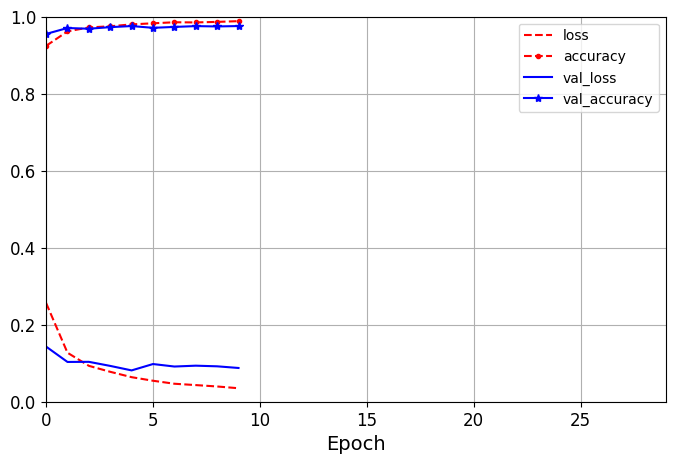

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Plot training and validation loss over epochs
pd.DataFrame(history.history).plot(
    figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, xlabel="Epoch",
    style=["r--", "r--.", "b-", "b-*"])
plt.legend(loc="upper right")
plt.show()

In [ ]:
# Build Model Neural Network with Batch Normalization
model2 = tf.keras.Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(90, activation='relu'),
    BatchNormalization(),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

checkpoint_path = 'mnist_model_checkpoint.h5'
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, monitor='val_accuracy', mode='max')

history = model2.fit(mnist_train_images, mnist_train_labels, epochs=20, validation_split=0.2, callbacks=[checkpoint])

test_loss, test_acc = model2.evaluate(mnist_test_images, mnist_test_labels)

Epoch 1/20
1500/1500 [==============================] - 9s 5ms/step - loss: 0.2423 - accuracy: 0.9282 - val_loss: 0.1439 - val_accuracy: 0.9580
Epoch 2/20
1500/1500 [==============================] - 8s 6ms/step - loss: 0.1129 - accuracy: 0.9654 - val_loss: 0.1127 - val_accuracy: 0.9663
Epoch 3/20
1500/1500 [==============================] - 8s 5ms/step - loss: 0.0786 - accuracy: 0.9758 - val_loss: 0.0904 - val_accuracy: 0.9739
Epoch 4/20
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0637 - accuracy: 0.9801 - val_loss: 0.1000 - val_accuracy: 0.9720
Epoch 5/20
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0515 - accuracy: 0.9840 - val_loss: 0.1048 - val_accuracy: 0.9714
Epoch 6/20
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0459 - accuracy: 0.9858 - val_loss: 0.1036 - val_accuracy: 0.9722
Epoch 7/20
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0344 - accuracy: 0.9889 - val_loss: 0.0976 - val_accuracy:

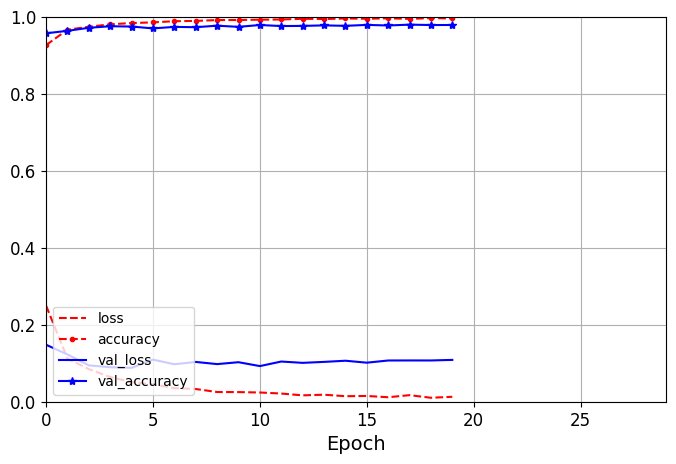

In [ ]:
pd.DataFrame(history.history).plot(
    figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, xlabel="Epoch",
    style=["r--", "r--.", "b-", "b-*"])
plt.legend(loc="lower left")
plt.show()

In [ ]:
# Feedforward Neural Network with Batch Normalization
model3 = tf.keras.Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(90, activation='relu'),
    Dropout(0.2),
    BatchNormalization(),
    Dense(10, activation='softmax')
])

model3.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_path = 'mnist_model_checkpoint.h5'
checkpoint = ModelCheckpoint(checkpoint_path, save_best_only=True, monitor='val_accuracy', mode='max')

history = model3.fit(mnist_train_images, mnist_train_labels, epochs=15, validation_split=0.2, callbacks=[checkpoint])

test_loss, test_acc = model3.evaluate(mnist_test_images, mnist_test_labels)

Epoch 1/15
1500/1500 [==============================] - 11s 6ms/step - loss: 0.3741 - accuracy: 0.8876 - val_loss: 0.1435 - val_accuracy: 0.9570
Epoch 2/15
1500/1500 [==============================] - 8s 6ms/step - loss: 0.1838 - accuracy: 0.9444 - val_loss: 0.1142 - val_accuracy: 0.9679
Epoch 3/15
1500/1500 [==============================] - 8s 5ms/step - loss: 0.1464 - accuracy: 0.9564 - val_loss: 0.1047 - val_accuracy: 0.9690
Epoch 4/15
1500/1500 [==============================] - 10s 7ms/step - loss: 0.1262 - accuracy: 0.9609 - val_loss: 0.0896 - val_accuracy: 0.9740
Epoch 5/15
1500/1500 [==============================] - 8s 6ms/step - loss: 0.1082 - accuracy: 0.9676 - val_loss: 0.0919 - val_accuracy: 0.9736
Epoch 6/15
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0981 - accuracy: 0.9701 - val_loss: 0.0907 - val_accuracy: 0.9732
Epoch 7/15
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0917 - accuracy: 0.9712 - val_loss: 0.0882 - val_accurac

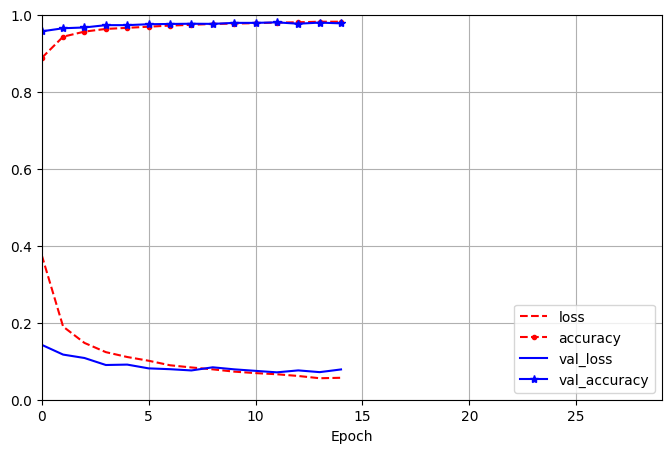

In [ ]:
pd.DataFrame(history.history).plot(
    figsize=(8, 5), xlim=[0, 29], ylim=[0, 1], grid=True, xlabel="Epoch",
    style=["r--", "r--.", "b-", "b-*"])
plt.legend(loc="lower right")
plt.show()

# 5- Hyperparameter Tuning and Overfitting Mitigation

In [ ]:
pip install tensorflow==2.12.0

###Hyperparameter tuning using Grid Search:

In [ ]:
from sklearn.model_selection import GridSearchCV
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier


def create_model(optimizer='adam', units=128):
    model = tf.keras.Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(units, activation='relu'),
        BatchNormalization(),
        Dense(10, activation='softmax')
    ])
    model.compile(optimizer=optimizer, loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


model = KerasClassifier(build_fn=create_model, epochs=10, validation_split=0.2, verbose=1)


param_grid = {
    'optimizer': ['adam', 'rmsprop'],
    'units': [64, 128, 256]
}

grid_search = GridSearchCV(estimator=model, param_grid=param_grid, cv=3)
grid_search_result = grid_search.fit(mnist_train_images, mnist_train_labels)


print("Best: %f using %s" % (grid_search_result.best_score_, grid_search_result.best_params_))

<ipython-input-7-fa582769abf0>:16: DeprecationWarning: KerasClassifier is deprecated, use Sci-Keras (https://github.com/adriangb/scikeras) instead. See https://www.adriangb.com/scikeras/stable/migration.html for help migrating.
  model = KerasClassifier(build_fn=create_model, epochs=10, validation_split=0.2, verbose=1)


Epoch 1/10
1000/1000 [==============================] - 8s 7ms/step - loss: 0.3659 - accuracy: 0.8935 - val_loss: 0.1791 - val_accuracy: 0.9470
Epoch 2/10
1000/1000 [==============================] - 6s 6ms/step - loss: 0.1832 - accuracy: 0.9463 - val_loss: 0.1452 - val_accuracy: 0.9564
Epoch 3/10
1000/1000 [==============================] - 5s 5ms/step - loss: 0.1382 - accuracy: 0.9589 - val_loss: 0.1116 - val_accuracy: 0.9674
Epoch 4/10
1000/1000 [==============================] - 6s 6ms/step - loss: 0.1168 - accuracy: 0.9652 - val_loss: 0.1194 - val_accuracy: 0.9621
Epoch 5/10
1000/1000 [==============================] - 6s 6ms/step - loss: 0.0965 - accuracy: 0.9700 - val_loss: 0.1153 - val_accuracy: 0.9647
Epoch 6/10
1000/1000 [==============================] - 6s 6ms/step - loss: 0.0823 - accuracy: 0.9747 - val_loss: 0.1020 - val_accuracy: 0.9686
Epoch 7/10
1000/1000 [==============================] - 5s 5ms/step - loss: 0.0739 - accuracy: 0.9758 - val_loss: 0.0993 - val_accuracy:

###Apply early stopping:

In [ ]:
model_dropout = tf.keras.Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dense(10, activation='softmax')
])

model_dropout.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])


early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)


history_dropout = model_dropout.fit(mnist_train_images, mnist_train_labels, epochs=10, validation_split=0.2, callbacks=[early_stopping])


best_val_loss = min(history_dropout.history['val_loss'])
best_epoch = history_dropout.history['val_loss'].index(best_val_loss) + 1


print(f"Best Validation Loss: {best_val_loss} at epoch {best_epoch}")
print(f"Best Training Accuracy: {max(history_dropout.history['accuracy'])}")

Epoch 1/10
1500/1500 [==============================] - 6s 3ms/step - loss: 0.2622 - accuracy: 0.9223 - val_loss: 0.1545 - val_accuracy: 0.9587
Epoch 2/10
1500/1500 [==============================] - 6s 4ms/step - loss: 0.1311 - accuracy: 0.9617 - val_loss: 0.1293 - val_accuracy: 0.9651
Epoch 3/10
1500/1500 [==============================] - 5s 3ms/step - loss: 0.0977 - accuracy: 0.9711 - val_loss: 0.1096 - val_accuracy: 0.9698
Epoch 4/10
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0845 - accuracy: 0.9739 - val_loss: 0.0990 - val_accuracy: 0.9712
Epoch 5/10
1500/1500 [==============================] - 5s 4ms/step - loss: 0.0678 - accuracy: 0.9791 - val_loss: 0.1088 - val_accuracy: 0.9700
Epoch 6/10
1500/1500 [==============================] - 9s 6ms/step - loss: 0.0569 - accuracy: 0.9822 - val_loss: 0.0955 - val_accuracy: 0.9742
Epoch 7/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0527 - accuracy: 0.9834 - val_loss: 0.1068 - val_accuracy:

###Evaluate the tuned model's performance and compare it with the baseline and ensemble models:

In [ ]:
# Print the tuned model's performance with best parameters and accuracy
print(f"Best Validation Loss: {best_val_loss} at epoch {best_epoch}")
print(f"Best Training Accuracy in tuned Model Accuracy: {max(history_dropout.history['accuracy'])}")

# print baseline and ensemble models accuracy:
print("Baseline Model Logistic Regression Accuracy:", accuracy)
print("Ensemble Model Decision Tree Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Ensemble Model Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Ensemble Model SVM Accuracy:", accuracy_score(y_test, y_pred_svm))

# Evaluate the ensemble's performance:
print("Voting Classifier Accuracy:", ensemble_accuracy)

Best Validation Loss: 0.0876639112830162 at epoch 8
Best Training Accuracy in tuned Model Accuracy: 0.988979160785675
Baseline Model Logistic Regression Accuracy: 0.9667142857142857
Ensemble Model Decision Tree Accuracy: 0.8681428571428571
Ensemble Model Random Forest Accuracy: 0.9667142857142857
Ensemble Model SVM Accuracy: 0.9622380952380952
Voting Classifier Accuracy: 0.9676666666666667


**The resutl of compare**
the tuned model achieved a best validation loss of 0.08% at epoch 6 with a training accuracy of 98.9%. In comparison, the Logistic Regression baseline model achieved an accuracy of 91.29%, the Decision Tree ensemble model achieved 86.81%, the Random Forest ensemble model achieved 96.67%, the SVM ensemble model achieved 96.67%, and the Voting Classifier achieved 97.2% accuracy.

# 6- Features Transoformation

In [ ]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from tensorflow.keras.utils import to_categorical
from sklearn.neural_network import MLPClassifier
import tensorflow as tf

#Load data for PCA
(mnist_train_images, mnist_train_labels), (mnist_test_images, mnist_test_labels) = tf.keras.datasets.mnist.load_data()
#split
X_train, X_val, y_train, y_val = train_test_split(mnist_train_images, mnist_train_labels, test_size=0.2, random_state=42)
#reshape
x_train_1 = X_train.reshape(X_train.shape[0], -1).astype(np.float32) / 255.0
x_val_1 = X_val.reshape(X_val.shape[0], -1).astype(np.float32) / 255.0
x_test_1= mnist_test_images.reshape( mnist_test_images.shape[0], -1).astype(np.float32)/255.0

11490434/11490434 [==============================] - 0s 0us/step


<ipython-input-4-cabe6772941c>:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_train.astype(int), cmap=plt.cm.get_cmap("jet"))


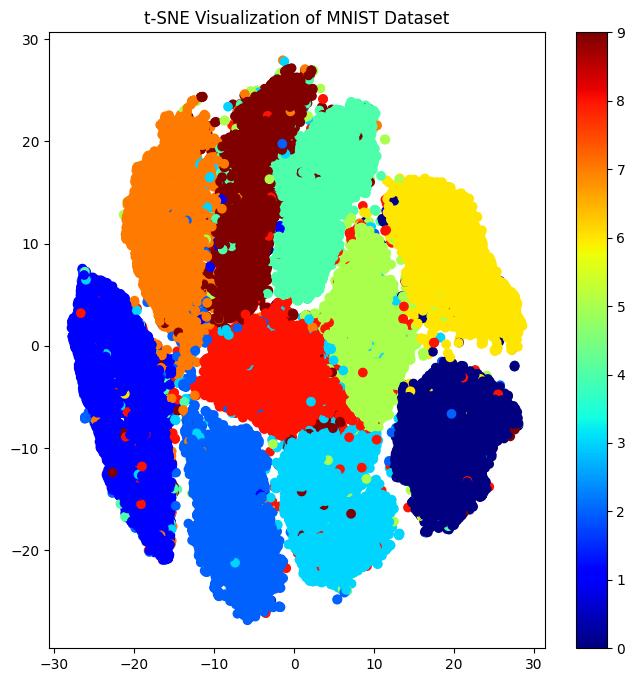

In [ ]:
pca = PCA(n_components=50)
x_train_pca = pca.fit_transform(x_train_1)
x_val_pca = pca.transform(x_val_1)
x_test_pca = pca.transform(x_test_1)

tsne = TSNE(n_components=2, random_state=42, n_iter=380)
X_tsne = tsne.fit_transform(x_train_1)

plt.figure(figsize=(8, 8))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_train.astype(int), cmap=plt.cm.get_cmap("jet"))
plt.colorbar(ticks=range(10))
plt.title('t-SNE Visualization of MNIST Dataset')
plt.show()

In [ ]:
# Train a neural network model on the PCA-transformed data
model_pca = Sequential([
    Dense(128, activation='relu', input_shape=(x_train_pca.shape[1],)),
    BatchNormalization(),
    Dense(10, activation='softmax')
])

model_pca.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history_pca = model_pca.fit(x_train_pca, y_train, epochs=10, validation_data=(x_val_pca, y_val), callbacks=[early_stopping])


# Evaluate the PCA-transformed model
loss_pca, acc_pca = model_pca.evaluate(x_test_pca, mnist_test_labels, verbose=1)
print(f"PCA Transformed Model - Test Loss: {loss_pca}, Test Accuracy: {acc_pca}")

Epoch 1/10
1500/1500 [==============================] - 6s 3ms/step - loss: 0.3417 - accuracy: 0.9006 - val_loss: 0.1556 - val_accuracy: 0.9555
Epoch 2/10
1500/1500 [==============================] - 5s 3ms/step - loss: 0.1472 - accuracy: 0.9565 - val_loss: 0.1102 - val_accuracy: 0.9682
Epoch 3/10
1500/1500 [==============================] - 4s 3ms/step - loss: 0.1077 - accuracy: 0.9678 - val_loss: 0.0938 - val_accuracy: 0.9721
Epoch 4/10
1500/1500 [==============================] - 5s 3ms/step - loss: 0.0877 - accuracy: 0.9731 - val_loss: 0.0887 - val_accuracy: 0.9741
Epoch 5/10
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0752 - accuracy: 0.9771 - val_loss: 0.0827 - val_accuracy: 0.9754
Epoch 6/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.0676 - accuracy: 0.9788 - val_loss: 0.0779 - val_accuracy: 0.9776
Epoch 7/10
1500/1500 [==============================] - 3s 2ms/step - loss: 0.0615 - accuracy: 0.9806 - val_loss: 0.0767 - val_accuracy:

# 7- **Conclusion:**






* Based on the  results of comparison between the baseline and ensemble models, here is the conclusion: The Ensemble model outperforms the baseline model with 96.76% Accuracy Compared to the baseline model ( Logistic Regression ) which achieved 91.29% Accuracy.







* The tuned neural network, which achieved a best validation loss of 0.08% at epoch 6 and a training accuracy of 98.9%, outperformed all other models including the baseline Logistic Regression and traditional machine learning algorithms such as Decision Trees, Random Forests, and Support Vector Machines. This underscores the effectiveness of the neural network in the given task, surpassing the performance of alternative models in terms of both validation loss and training accuracy.

* After training a tuned model on the PCA-transformed data. achieves a test loss of 0.07% and a test accuracy of 98.04%. This demonstrates that even after reducing the dimensionality of the data using PCA, the model can still achieve high accuracy on the test set.